
	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

Healthy vs. LR vs. HR

Cancer: 96 entries
High risk: 29 entries
Low risk: 41 entries
Available cases: ['Cancer' 'High risk' 'Low risk']
Coding: -> forward
{'Cancer': [1, 0, 0], 'High risk': [0, 1, 0], 'Low risk': [0, 0, 1]}


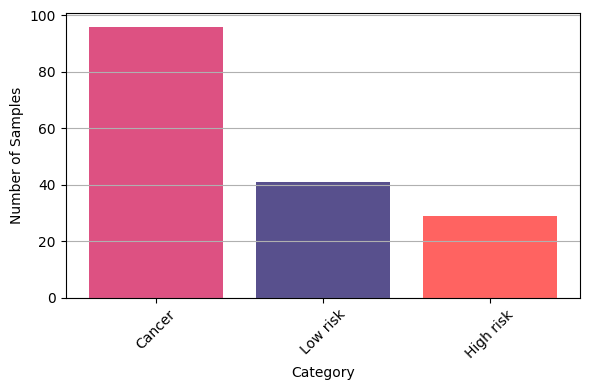


Inverse mapping: {(1, 0, 0): 'Cancer', (0, 1, 0): 'High risk', (0, 0, 1): 'Low risk'}
(166, 31, 7728) (166, 3) (166,)


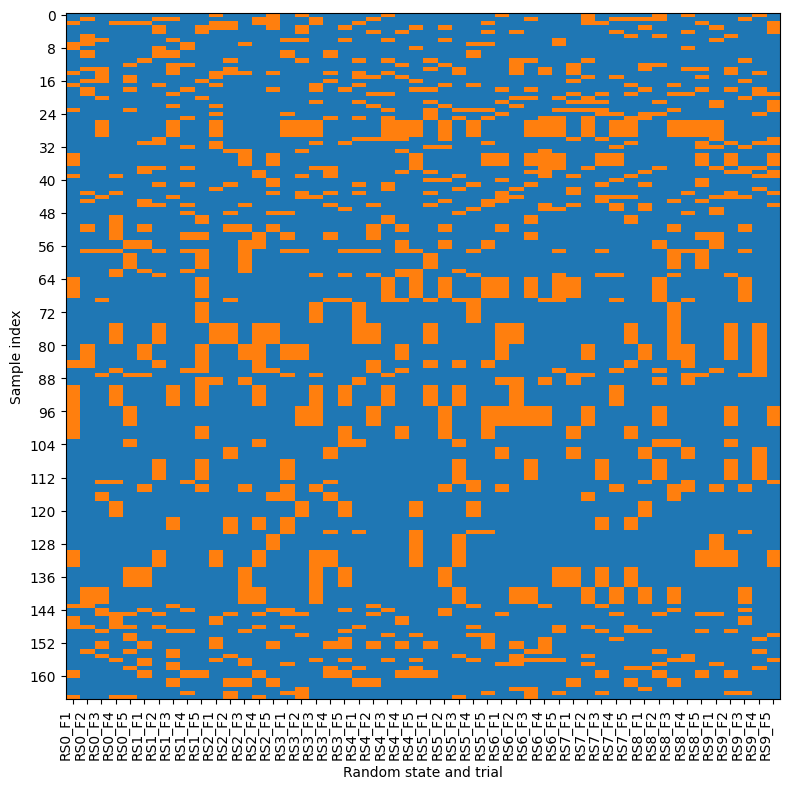

In [12]:
from toolbox.results import Results_data_loading
from toolbox.visualization import plot_cv_heatmap

class_task = "healthy_vs_cancer"
class_task = "cancer_vs_lr_hr"
# class_task = "MC"

X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)

n_trials = 10
n_folds = 5

plot_cv_heatmap(X, Y_labels, Case, n_trials, n_folds)

In [13]:
# combine IIVV-analysis results
from glob import glob

import pandas as pd

csv_files = glob(f"results/freq-analysis_*_gpu.csv")
print(csv_files)

['results/freq-analysis_rs_healthy_vs_cancer_gpu.csv', 'results/freq-analysis_rs_MC_gpu.csv', 'results/freq-analysis_rs_cancer_vs_lr_hr_gpu.csv']


In [14]:
for fls in csv_files:
    print(fls)

results/freq-analysis_rs_healthy_vs_cancer_gpu.csv
results/freq-analysis_rs_MC_gpu.csv
results/freq-analysis_rs_cancer_vs_lr_hr_gpu.csv


In [21]:
df_list = [pd.read_csv(file) for file in csv_files]
combined_df = pd.concat(df_list, ignore_index=True)

In [22]:
len(combined_df)

150

In [23]:
combined_df

,Task,rs,Fold,fold_auc_results,avg_fold_auc_results,fold_top_freq_indices,composite_freq_indices
0,healthy_vs_cancer,0,1,[0.81153846 0.825 0.82307692 0.82307692 0...,0.812965,[ 0 30 12 13 8 10 11 15 16 19 29 28 1 27 23 ...,[ 0 30 12 13 8 10 11 15 16 19 29 28 1 27 23 ...
1,healthy_vs_cancer,0,2,[0.65123457 0.74691358 0.92283951 0.91666667 0...,0.890183,[30 27 0 29 12 13 8 28 26 16 25 17 1 10 24 ...,[30 27 0 29 12 13 8 28 26 16 25 17 1 10 24 ...
2,healthy_vs_cancer,0,3,[0.58235294 0.69117647 0.85588235 0.83529412 0...,0.816509,[30 27 0 29 12 28 11 8 13 10 26 16 25 1 24 ...,[30 27 0 29 12 28 11 8 13 10 26 16 25 1 24 ...
3,healthy_vs_cancer,0,4,[0.79468599 0.86714976 0.95169082 0.9468599 0...,0.935484,[30 27 0 29 12 13 8 28 16 11 26 10 25 17 1 ...,[30 27 0 29 12 13 8 28 16 11 26 10 25 17 1 ...
4,healthy_vs_cancer,0,5,[0.71176471 0.75294118 0.80588235 0.80588235 0...,0.794307,[30 27 0 29 8 10 12 28 26 13 1 25 24 7 11 ...,[30 27 0 29 8 10 12 28 26 13 1 25 24 7 11 ...
...,...,...,...,...,...,...,...
145,cancer_vs_lr_hr,9,1,[0.60194665 0.69086945 0.71556484 0.75320792 0...,0.649995,[30 7 0 12 29 8 13 28 16 24 9 27 15 20 19 ...,[30 7 0 12 29 8 13 28 16 24 9 27 15 20 19 ...
146,cancer_vs_lr_hr,9,2,[0.57038809 0.65419989 0.65547581 0.636563 0...,0.643065,[30 7 0 27 29 28 8 26 12 17 21 25 1 24 9 ...,[30 7 0 27 29 28 8 26 12 17 21 25 1 24 9 ...
147,cancer_vs_lr_hr,9,3,[0.78221038 0.8010249 0.77576868 0.78408998 0...,0.788618,[ 7 0 30 12 8 13 27 22 11 16 29 9 20 25 26 ...,[ 7 0 30 12 8 13 27 22 11 16 29 9 20 25 26 ...
148,cancer_vs_lr_hr,9,4,[0.68425926 0.66234568 0.70246914 0.82026749 0...,0.735411,[30 27 0 7 29 8 28 1 11 23 14 24 12 25 26 ...,[30 27 0 7 29 8 28 1 11 23 14 24 12 25 26 ...


In [25]:
combined_df.to_csv(f"results/freq-analysis.csv", index=False)

## Create plots

In [26]:
import pandas as pd
from toolbox.Freq_reduction import (
    plot_fold_rankings_rework,
    plot_no_of_top_frequencies_rework,
    select_random_state,
)
import numpy as np

In [27]:
df_all = pd.read_csv(f"results/freq-analysis.csv")
df_all

,Task,rs,Fold,fold_auc_results,avg_fold_auc_results,fold_top_freq_indices,composite_freq_indices
0,healthy_vs_cancer,0,1,[0.81153846 0.825 0.82307692 0.82307692 0...,0.812965,[ 0 30 12 13 8 10 11 15 16 19 29 28 1 27 23 ...,[ 0 30 12 13 8 10 11 15 16 19 29 28 1 27 23 ...
1,healthy_vs_cancer,0,2,[0.65123457 0.74691358 0.92283951 0.91666667 0...,0.890183,[30 27 0 29 12 13 8 28 26 16 25 17 1 10 24 ...,[30 27 0 29 12 13 8 28 26 16 25 17 1 10 24 ...
2,healthy_vs_cancer,0,3,[0.58235294 0.69117647 0.85588235 0.83529412 0...,0.816509,[30 27 0 29 12 28 11 8 13 10 26 16 25 1 24 ...,[30 27 0 29 12 28 11 8 13 10 26 16 25 1 24 ...
3,healthy_vs_cancer,0,4,[0.79468599 0.86714976 0.95169082 0.9468599 0...,0.935484,[30 27 0 29 12 13 8 28 16 11 26 10 25 17 1 ...,[30 27 0 29 12 13 8 28 16 11 26 10 25 17 1 ...
4,healthy_vs_cancer,0,5,[0.71176471 0.75294118 0.80588235 0.80588235 0...,0.794307,[30 27 0 29 8 10 12 28 26 13 1 25 24 7 11 ...,[30 27 0 29 8 10 12 28 26 13 1 25 24 7 11 ...
...,...,...,...,...,...,...,...
145,cancer_vs_lr_hr,9,1,[0.60194665 0.69086945 0.71556484 0.75320792 0...,0.649995,[30 7 0 12 29 8 13 28 16 24 9 27 15 20 19 ...,[30 7 0 12 29 8 13 28 16 24 9 27 15 20 19 ...
146,cancer_vs_lr_hr,9,2,[0.57038809 0.65419989 0.65547581 0.636563 0...,0.643065,[30 7 0 27 29 28 8 26 12 17 21 25 1 24 9 ...,[30 7 0 27 29 28 8 26 12 17 21 25 1 24 9 ...
147,cancer_vs_lr_hr,9,3,[0.78221038 0.8010249 0.77576868 0.78408998 0...,0.788618,[ 7 0 30 12 8 13 27 22 11 16 29 9 20 25 26 ...,[ 7 0 30 12 8 13 27 22 11 16 29 9 20 25 26 ...
148,cancer_vs_lr_hr,9,4,[0.68425926 0.66234568 0.70246914 0.82026749 0...,0.735411,[30 27 0 7 29 8 28 1 11 23 14 24 12 25 26 ...,[30 27 0 7 29 8 28 1 11 23 14 24 12 25 26 ...


In [28]:
# select specific task
class_task = "healthy_vs_cancer"
class_task = "cancer_vs_lr_hr"
# class_task = "MC"

df = df_all.loc[df_all["Task"] == class_task]

In [29]:
random_state = 0

select_random_state(df, random_state)

,Task,rs,Fold,fold_auc_results,avg_fold_auc_results,fold_top_freq_indices,composite_freq_indices
100,cancer_vs_lr_hr,0,1,[0.53901515 0.54186027 0.62683502 0.56779461 0...,0.573517,[ 7 0 30 12 8 26 23 27 13 16 29 15 24 20 11 ...,[ 7 0 30 12 8 26 23 27 13 16 29 15 24 20 11 ...
101,cancer_vs_lr_hr,0,2,[0.59775861 0.74489026 0.75116152 0.73128481 0...,0.749218,[30 7 0 12 29 8 13 26 28 16 9 27 1 11 17 ...,[30 7 0 12 29 8 13 26 28 16 9 27 1 11 17 ...
102,cancer_vs_lr_hr,0,3,[0.69214024 0.74498805 0.7623702 0.76129821 0...,0.741106,[30 27 0 29 12 26 28 25 13 16 21 1 8 23 22 ...,[30 27 0 29 12 26 28 25 13 16 21 1 8 23 22 ...
103,cancer_vs_lr_hr,0,4,[0.61177419 0.64086456 0.65318942 0.71794884 0...,0.669286,[30 7 0 12 29 13 8 28 16 9 24 27 20 21 11 ...,[30 7 0 12 29 13 8 28 16 9 24 27 20 21 11 ...
104,cancer_vs_lr_hr,0,5,[0.7164533 0.83304473 0.79047804 0.80332507 0...,0.823978,[30 7 0 29 12 8 13 28 26 11 16 9 27 10 1 ...,[30 7 0 29 12 8 13 28 26 11 16 9 27 10 1 ...


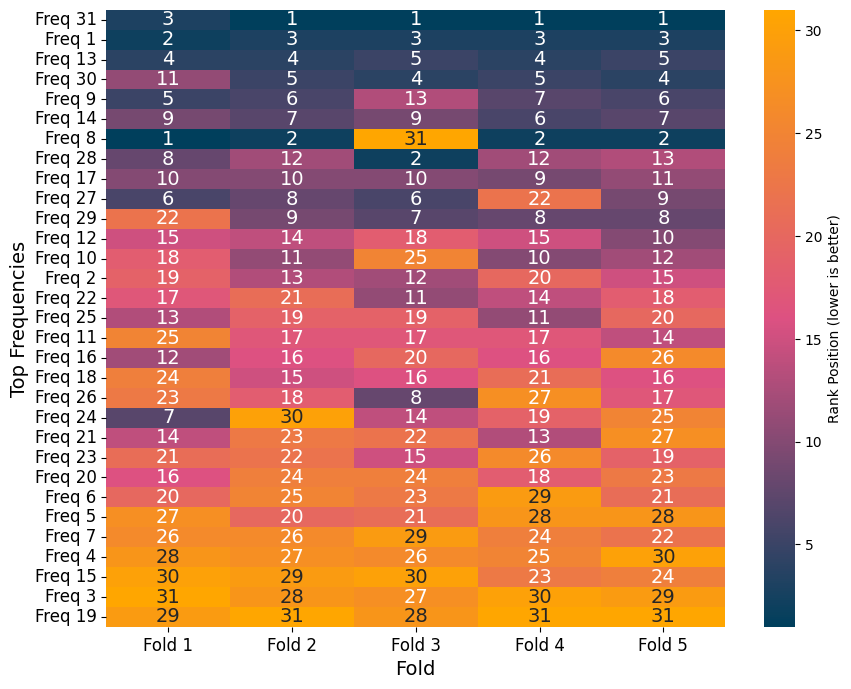

In [30]:
plot_fold_rankings_rework(df, random_state, class_task)

                Task  rs  Fold  \
100  cancer_vs_lr_hr   0     1   
101  cancer_vs_lr_hr   0     2   
102  cancer_vs_lr_hr   0     3   
103  cancer_vs_lr_hr   0     4   
104  cancer_vs_lr_hr   0     5   

                                      fold_auc_results  avg_fold_auc_results  \
100  [0.53901515 0.54186027 0.62683502 0.56779461 0...              0.573517   
101  [0.59775861 0.74489026 0.75116152 0.73128481 0...              0.749218   
102  [0.69214024 0.74498805 0.7623702  0.76129821 0...              0.741106   
103  [0.61177419 0.64086456 0.65318942 0.71794884 0...              0.669286   
104  [0.7164533  0.83304473 0.79047804 0.80332507 0...              0.823978   

                                 fold_top_freq_indices  \
100  [ 7  0 30 12  8 26 23 27 13 16 29 15 24 20 11 ...   
101  [30  7  0 12 29  8 13 26 28 16  9 27  1 11 17 ...   
102  [30 27  0 29 12 26 28 25 13 16 21  1  8 23 22 ...   
103  [30  7  0 12 29 13  8 28 16  9 24 27 20 21 11 ...   
104  [30  7  0 29 12  8 

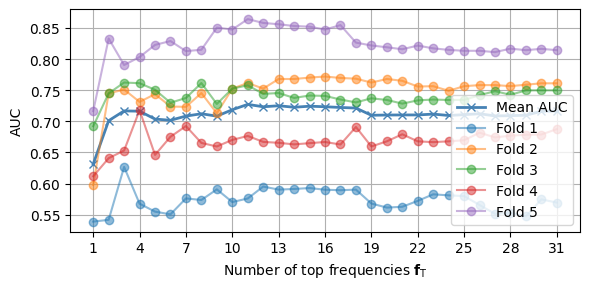

In [31]:
plot_no_of_top_frequencies_rework(df, random_state, class_task)

In [32]:
import matplotlib.pyplot as plt
from toolbox import get_freqs
from toolbox.Freq_reduction import select_composite_freq_indices

In [33]:
freq_idx, freq_list = get_freqs(plot=False)

In [34]:
all_top_freqs_baseline = select_composite_freq_indices(df, random_state)
print(all_top_freqs_baseline)
top_freqs_baseline = all_top_freqs_baseline[1]
print(top_freqs_baseline)

[[ 7  0 30 12  8 26 23 27 13 16 29 15 24 20 11 19 21  9  1  5 22 28 25 17
  10  6  4  3 18 14  2]
 [30  7  0 12 29  8 13 26 28 16  9 27  1 11 17 15 10 25 24  4 21 22 20 19
   5  6  3  2 14 23 18]
 [30 27  0 29 12 26 28 25 13 16 21  1  8 23 22 17 10 11 24 15  4 20  5 19
   9  3  2 18  6 14  7]
 [30  7  0 12 29 13  8 28 16  9 24 27 20 21 11 15 10 19 23  1 17 26 14  6
   3 22 25  4  5  2 18]
 [30  7  0 29 12  8 13 28 26 11 16  9 27 10  1 17 25 21 22 24  5  6 19 14
  23 15 20  4  2  3 18]]
[30  7  0 12 29  8 13 26 28 16  9 27  1 11 17 15 10 25 24  4 21 22 20 19
  5  6  3  2 14 23 18]


In [35]:
class_task

'cancer_vs_lr_hr'

In [36]:
np.savez(
    f"results/freq_fold_results_{class_task}.npz", top_freqs_baseline=top_freqs_baseline
)

NameError: name 'top_2' is not defined

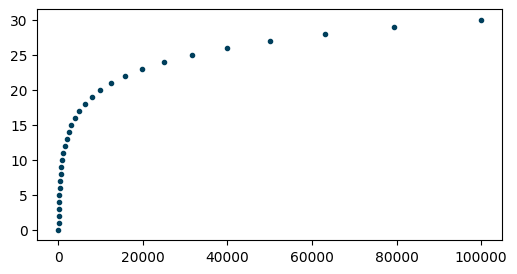

In [37]:
plt.figure(figsize=(6, 3))
plt.plot(freq_list[freq_idx], freq_idx, ".", c="#003F5C", ms=6, label="All")
plt.plot(freq_list[top_2], top_2, "o", c="#58508D", ms=9.5, label="Top 2")
plt.plot(freq_list[top_3], top_3, "x", c="#7A5195", ms=9.5, label="Top 3")
plt.plot(freq_list[top_5], top_5, "X", c="#FF6361", ms=8, label="Top 5")
plt.plot(freq_list[top_12], top_12, "*", c="#FFA600", ms=8, label="Top 12")
plt.legend()
plt.grid()
plt.xlabel("Frequency (Hz)")
plt.xscale("log")
plt.ylabel("Frequency index")
plt.tight_layout()
plt.savefig(f"results/freq_topX_{class_task}.pdf", bbox_inches="tight")
plt.show()

### Test top2, top3, top5, top12, all (Baseline)

In [21]:
Freq_sel = {
    "Top 2": top_2,
    "Top 3": top_3,
    "Top 5": top_5,
    "Top 12": top_12,
    "All": top_freqs_baseline,  # np.arange(31), # it doesn't matter
}

NameError: name 'top_2' is not defined

In [22]:
results = []
numXparams = []
for Fsel, idxs in Freq_sel.items():
    numXparams.append({"Fsel": Fsel, "n_params": len(X[0, idxs, :].flatten())})
    for trial in range(7):
        print("Trial:", trial, "\n\t", Fsel, idxs)

        avg_roc_auc, _ = compute_ROC_patient_split(
            X[:, idxs, :],
            Y,
            patient_ids=Case,
            test_size=0.2,
            plot=False,
            random_state=trial,
            inverse_mapping=inverse_mapping,
        )

        results.append({"Fsel": Fsel, "Trial": trial + 1, "avg. ROC AUC": avg_roc_auc})


df_results = pd.DataFrame(results)
df_params = pd.DataFrame(numXparams)

df_results.to_csv(f"results/freq-analysis_{class_task}.csv", index=False)
df_params.to_csv(f"results/freq-analysis_{class_task}_params.csv", index=False)

NameError: name 'Freq_sel' is not defined

In [ ]:
plt.figure(figsize=(6, 3))
sns.heatmap(
    df_pivot, annot=True, cmap=cmap, fmt=".2f", cbar_kws={"label": "avg. ROC AUC"}
)

plt.ylabel("Selected frequencies")
plt.xlabel("Trial")
plt.tight_layout()
# title: Average AUC Heatmap
# plt.savefig("results/auc_heatmap_freq_sel.pdf", bbox_inches="tight")
plt.show()

In [ ]:
df_results = pd.read_csv(f"results/freq-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/freq-analysis_{class_task}_params.csv")

In [ ]:
df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "Mean AUC"}, ax=ax0
)
ax0.set_ylabel("Selected frequencies")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Average AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Fsel"],
        markersize=8,
    )
ax1.set_xlabel("Input data points $N_{input}$\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
# ax1.set_xscale('log')

ax1.legend(title="Freq. selection")
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
df_plot

___

**Code for statistical evaluation of the impact of $\mathbf{f}_\mathrm{T}$**

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import auc, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import label_binarize
from sklearn.svm import SVC
from toolbox.evaluation import load_top_Fsel_Msel
from toolbox.results import Results_data_loading
from tqdm import tqdm

In [ ]:
class_task = "healthy_vs_cancer"

stats = []

Freq_sel, _ = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)
print(Freq_sel)
for Fsel in Freq_sel.keys():
    X_tmp = X[:, Freq_sel[Fsel], :]
    X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
    for rs in tqdm(range(20)):
        m = SVC(probability=True, random_state=0)
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
        for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
            m.fit(X_train, y_train)
            probs = m.predict_proba(X_test)[:, 1]
            auc = roc_auc_score(y_test, probs)
            stats.append({"Task": class_task, "Fsel": Fsel, "rs": rs, "auc": auc})

df_stats = pd.DataFrame(stats)
df_stats.to_csv(f"results/freq-analysis_{class_task}_statistics.csv", index=False)


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 

Healthy vs. LR vs. HR

Cancer: 96 entries
High risk: 29 entries
Low risk: 41 entries
Available cases: ['Cancer' 'High risk' 'Low risk']
Coding: -> forward
{'Cancer': [1, 0, 0], 'High risk': [0, 1, 0], 'Low risk': [0, 0, 1]}


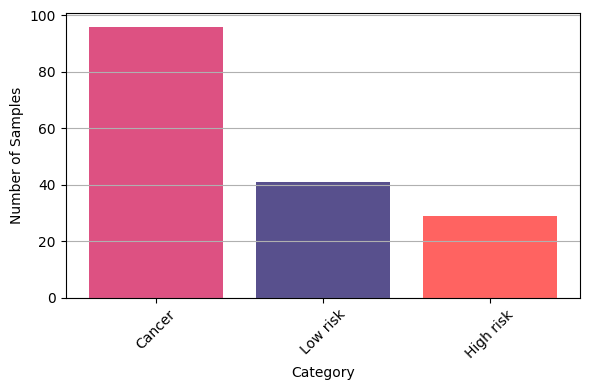


Inverse mapping: {(1, 0, 0): 'Cancer', (0, 1, 0): 'High risk', (0, 0, 1): 'Low risk'}
(166, 31, 7728) (166, 3) (166,)
{'Top 1': [30], 'Top 2': [30, 7], 'Top 3': [30, 7, 0], 'Top 4': [30, 7, 0, 12], 'Top 5': [30, 7, 0, 12, 29], 'Top 6': [30, 7, 0, 12, 29, 8], 'Top 7': [30, 7, 0, 12, 29, 8, 13], 'Top 8': [30, 7, 0, 12, 29, 8, 13, 26], 'Top 9': [30, 7, 0, 12, 29, 8, 13, 26, 28], 'Top 10': [30, 7, 0, 12, 29, 8, 13, 26, 28, 16], 'Top 11': [30, 7, 0, 12, 29, 8, 13, 26, 28, 16, 9], 'Top 12': [30, 7, 0, 12, 29, 8, 13, 26, 28, 16, 9, 27], 'Top 13': [30, 7, 0, 12, 29, 8, 13, 26, 28, 16, 9, 27, 1], 'Top 14': [30, 7, 0, 12, 29, 8, 13, 26, 28, 16, 9, 27, 1, 11], 'Top 15': [30, 7, 0, 12, 29, 8, 13, 26, 28, 16, 9, 27, 1, 11, 17], 'Top 16': [30, 7, 0, 12, 29, 8, 13, 26, 28, 16, 9, 27, 1, 11, 17, 15], 'Top 17': [30, 7, 0, 12, 29, 8, 13, 26, 28, 16, 9, 27, 1, 11, 17, 15, 10], 'Top 18': [30, 7, 0, 12, 29, 8, 13, 26, 28, 16, 9, 27, 1, 11, 17, 15, 10, 25], 'Top 19': [30, 7, 0, 12, 29, 8, 13, 26, 28, 16, 9

 35%|██████████████████████████████████████▏                                                                      | 7/20 [01:39<03:10, 14.65s/it]

In [ ]:
class_task = "cancer_vs_lr_hr"

stats = []

Freq_sel, _ = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)
classes = np.unique(Y_labels)
print(Freq_sel)
for Fsel in Freq_sel.keys():
    X_tmp = X[:, Freq_sel[Fsel], :]
    X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
    for rs in tqdm(range(20)):
        m = SVC(probability=True, random_state=0)
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
        for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
            m.fit(X_train, y_train)
            probs = m.predict_proba(X_test)  # shape (n_samples, n_classes)
            # Binarize true labels
            y_bin = label_binarize(
                y_test, classes=classes
            )  # shape (n_samples, n_classes)
            # Micro-average ROC
            fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
            roc_auc = auc(fpr, tpr)

            # Flip AUC if < 0.5
            if roc_auc < 0.5:
                fpr, tpr = 1 - fpr, 1 - tpr
                roc_auc = 1 - roc_auc

            stats.append({"Task": class_task, "Fsel": Fsel, "rs": rs, "auc": roc_auc})

df_stats = pd.DataFrame(stats)
df_stats.to_csv(f"results/freq-analysis_{class_task}_statistics.csv", index=False)

In [ ]:
class_task = "MC"

stats = []

Freq_sel, _ = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)
classes = np.unique(Y_labels)
print(Freq_sel)
for Fsel in Freq_sel.keys():
    X_tmp = X[:, Freq_sel[Fsel], :]
    X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
    for rs in tqdm(range(20)):
        m = SVC(probability=True, random_state=0)
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
        for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
            m.fit(X_train, y_train)
            probs = m.predict_proba(X_test)  # shape (n_samples, n_classes)
            # Binarize true labels
            y_bin = label_binarize(
                y_test, classes=classes
            )  # shape (n_samples, n_classes)
            # Micro-average ROC
            fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
            roc_auc = auc(fpr, tpr)

            # Flip AUC if < 0.5
            if roc_auc < 0.5:
                fpr, tpr = 1 - fpr, 1 - tpr
                roc_auc = 1 - roc_auc

            stats.append({"Task": class_task, "Fsel": Fsel, "rs": rs, "auc": roc_auc})

df_stats = pd.DataFrame(stats)
df_stats.to_csv(f"results/freq-analysis_{class_task}_statistics.csv", index=False)

In [ ]:
tasks = ["healthy_vs_cancer", "cancer_vs_lr_hr", "MC"]

stats = []
Fsel = "All"

for class_task in tasks:
    print(class_task)
    X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
        class_task, data_augmentation=False
    )
    classes = np.unique(Y_labels)
    n_classes = len(classes)

    X_tmp = X[:, :, :]
    X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
    for rs in tqdm(range(20)):
        m = SVC(probability=True, random_state=0)
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
        for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
            m.fit(X_train, y_train)
            probs = m.predict_proba(X_test)
            if n_classes == 2:
                roc_auc = roc_auc_score(y_test, probs[:, 1])
            else:
                y_bin = label_binarize(y_test, classes=classes)
                # Micro-average ROC
                fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
                roc_auc = auc(fpr, tpr)

                # Flip AUC if < 0.5
                if roc_auc < 0.5:
                    fpr, tpr = 1 - fpr, 1 - tpr
                    roc_auc = 1 - roc_auc

            stats.append({"Task": class_task, "Fsel": Fsel, "rs": rs, "auc": roc_auc})

df_stats = pd.DataFrame(stats)
df_stats.to_csv(f"results/freq-analysis_{class_task}_ALL_statistics.csv", index=False)

___